# 05 · Demand forecasting per bottle size, with censored demand

**Question:** how many units of each full bottle (30, 50 and 100 ml; the 5 and 10 ml samples aren't
stock-tracked) will sell per day, and when should the shop reorder?

**Data:** `marts.fct_inventory_daily`, one row per size and Kyiv day, built from the #130 stock
ledger: units sold, closing stock, and `is_demand_censored` when the size was out of stock at some
point that day.

**Censored demand.** On a stock-out day, sales are only a *lower bound* of demand: shoppers who
wanted the bottle couldn't buy it (most took a 10 ml sample instead, 15 % ordered anyway as a
backorder). Using those days as ordinary sales would teach a model that demand is whatever stock
allowed. So censored days are **masked**: left out of training and evaluation, and never used as
lag inputs.

**Models:** a seasonal-naive baseline (same weekday last week, two weeks back if that day was
censored) against one global LightGBM model over all sizes with calendar features (8 March,
14 February, St Nicholas, New Year, Black Friday, gift seasons) and masked lags. Both forecast 7
days ahead (they only read sales at least 7 days old), the horizon of a weekly replenishment
decision. Scored with WAPE on non-censored days, over three 13-week rolling origins.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from jassmin_ml import metrics, plots, splits
from jassmin_ml.db import read_mart
from jassmin_ml.seed import SEED, set_seeds

set_seeds()
plots.use_style()
pd.set_option("display.precision", 3)

ORIGINS = ["2026-02-02", "2026-05-04", "2026-08-03"]  # Mondays; each test window is 13 weeks
TEST_WEEKS = 13

In [2]:
panel = read_mart(
    """
    select i.variant_id, i.product_key, i.volume_ml, i.day, i.units_sold::float8 as units_sold,
      i.is_demand_censored, i.closing_stock, i.backorder_units,
      p.popular_rank, p.gender, p.fragrance_family,
      d.month, d.day_of_week, d.is_weekend, d.is_womens_day, d.is_valentines_day, d.is_st_nicholas_day,
      d.is_new_year, d.is_black_friday, d.is_gift_season
    from marts.fct_inventory_daily i
    join marts.dim_products p using (product_key)
    join marts.dim_date d on d.date_day = i.day
    where i.day >= '2024-01-01'
    order by i.variant_id, i.day
    """
)
panel["day"] = pd.to_datetime(panel["day"])
panel = panel.reset_index(drop=True)
summary = pd.DataFrame(
    {
        "sizes": panel["variant_id"].nunique(),
        "days": panel["day"].nunique(),
        "units sold": panel["units_sold"].sum(),
        "days with a sale": (panel["units_sold"] > 0).mean(),
        "censored size-days": panel["is_demand_censored"].mean(),
    },
    index=["value"],
).T
summary

,value
sizes,384.000
days,1035.000
units sold,16941.000
days with a sale,0.036
censored size-days,0.042


Demand per size is **intermittent**: on most days a given bottle doesn't sell at all. Censored days
are about 4 % of size-days, but they cluster on the popular sizes, exactly where the demand is.

In [3]:
by_volume = panel.groupby("volume_ml").agg(
    units_per_day=("units_sold", "mean"), censored_share=("is_demand_censored", "mean")
)
top_quartile = panel.groupby("variant_id")["units_sold"].sum().pipe(lambda s: s[s >= s.quantile(0.75)].index)
by_volume.loc["top 25 % sizes by sales"] = [
    panel.loc[panel["variant_id"].isin(top_quartile), "units_sold"].mean(),
    panel.loc[panel["variant_id"].isin(top_quartile), "is_demand_censored"].mean(),
]
by_volume

,units_per_day,censored_share
volume_ml,,
30,0.056,0.062
50,0.046,0.045
100,0.026,0.020
top 25 % sizes by sales,0.100,0.124


## Features

Lags of 7, 14, 21 and 28 days and the mean of the previous 4 and 13 weeks, all computed on the
masked series (a censored day is missing, not zero), plus the calendar and the product.

In [4]:
LAGS = [7, 14, 21, 28]
lagged = splits.lag_masked(panel, "units_sold", "is_demand_censored", "variant_id", LAGS)
masked = splits.censor_mask(panel["units_sold"], panel["is_demand_censored"])
shifted = masked.groupby(panel["variant_id"]).shift(7)
grouped = shifted.groupby(panel["variant_id"])
features = pd.concat(
    [
        panel,
        lagged,
        grouped.transform(lambda s: s.rolling(28, min_periods=7).mean()).rename("mean_4w"),
        grouped.transform(lambda s: s.rolling(91, min_periods=28).mean()).rename("mean_13w"),
        grouped.transform(lambda s: s.rolling(364, min_periods=91).mean()).rename("mean_52w"),
    ],
    axis=1,
)
features["seasonal_naive"] = splits.seasonal_naive(panel, "units_sold", "is_demand_censored", "variant_id", season=7, fallbacks=1)
for column in ["gender", "fragrance_family"]:
    features[column] = pd.Categorical(features[column].fillna("unknown"))
CALENDAR = ["month", "day_of_week", "is_weekend", "is_womens_day", "is_valentines_day", "is_st_nicholas_day",
            "is_new_year", "is_black_friday", "is_gift_season"]
FEATURES = (
    ["volume_ml", "popular_rank", "gender", "fragrance_family"]
    + CALENDAR
    + [f"units_sold_lag{n}" for n in LAGS]
    + ["mean_4w", "mean_13w", "mean_52w"]
)
features[CALENDAR[2:]] = features[CALENDAR[2:]].astype(int)
features["days_to_womens_day"] = (
    pd.to_datetime(features["day"].dt.year.astype(str) + "-03-08") - features["day"]
).dt.days.where(lambda d: d.between(0, 21), -1)
features["days_to_new_year"] = (
    pd.to_datetime((features["day"].dt.year + (features["day"].dt.month > 1)).astype(str) + "-12-31")
    .where(features["day"].dt.month == 12, pd.NaT) - features["day"]
).dt.days.fillna(-1)
FEATURES += ["days_to_womens_day", "days_to_new_year"]
observed = ~features["is_demand_censored"]
print(f"{len(FEATURES)} features; {observed.mean():.1%} of size-days are observed (not censored)")

22 features; 95.8% of size-days are observed (not censored)


## Rolling-origin backtest

For each origin: train on every observed size-day before it (the last 8 weeks of that as early
stopping), forecast the next 13 weeks. Both models score the same rows: observed days where the
seasonal-naive forecast exists.

**Which WAPE?** WAPE = Σ|actual − forecast| / Σ actual is an absolute error, so the forecast that
minimises it is the *median* of demand. For one bottle on one day the median is 0: it sells on
about 4 % of days. At that level "always forecast 0" scores a WAPE of exactly 1.0 and beats any
honest forecast of the demand rate. So WAPE is reported at three levels:

1. **per size and day**, the raw level, next to the "always 0" reference and the RMSE (which rewards
   getting the *rate* right);
2. **per size and week**, the forecast's 7-day horizon and the level a replenishment decision uses;
3. **daily units per bottle size class** (30, 50, 100 ml) and for the whole shop, where demand is no
   longer intermittent.

In [5]:
PARAMS = dict(
    objective="tweedie", tweedie_variance_power=1.3, learning_rate=0.03, num_leaves=31,
    min_child_samples=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    n_estimators=3000, random_state=SEED, deterministic=True, force_row_wise=True, n_jobs=4, verbose=-1,
)  # fmt: skip


def backtest(origin: str) -> tuple[pd.DataFrame, lgb.LGBMRegressor]:
    start = pd.Timestamp(origin)
    end = start + pd.Timedelta(weeks=TEST_WEEKS)
    stop = start - pd.Timedelta(weeks=8)
    history = features[(features["day"] < start) & observed & features["mean_13w"].notna()]
    fit, early = history[history["day"] < stop], history[history["day"] >= stop]
    model = lgb.LGBMRegressor(**PARAMS)
    model.fit(
        fit[FEATURES], fit["units_sold"], eval_set=[(early[FEATURES], early["units_sold"])],
        callbacks=[lgb.early_stopping(150, verbose=False)],
    )  # fmt: skip
    window = features[(features["day"] >= start) & (features["day"] < end)].copy()
    window["lightgbm"] = model.predict(window[FEATURES])
    window["origin"] = origin
    return window, model


windows, models = zip(*(backtest(origin) for origin in ORIGINS))
test = pd.concat(windows, ignore_index=True)
scored = test[~test["is_demand_censored"] & test["seasonal_naive"].notna()]


def wape_table(frame: pd.DataFrame) -> pd.Series:
    return pd.Series(
        {
            "seasonal naive": metrics.wape(frame["units_sold"], frame["seasonal_naive"]),
            "LightGBM": metrics.wape(frame["units_sold"], frame["lightgbm"]),
            "units": frame["units_sold"].sum(),
        }
    )


def by_origin(frame: pd.DataFrame) -> pd.DataFrame:
    table = frame.groupby("origin").apply(wape_table)
    table.loc["all origins"] = wape_table(frame)
    return table


daily_wape = by_origin(scored)
daily_wape["always 0"] = 1.0
daily_wape["RMSE seasonal naive"] = [
    *(np.sqrt(((g["units_sold"] - g["seasonal_naive"]) ** 2).mean()) for _, g in scored.groupby("origin")),
    np.sqrt(((scored["units_sold"] - scored["seasonal_naive"]) ** 2).mean()),
]
daily_wape["RMSE LightGBM"] = [
    *(np.sqrt(((g["units_sold"] - g["lightgbm"]) ** 2).mean()) for _, g in scored.groupby("origin")),
    np.sqrt(((scored["units_sold"] - scored["lightgbm"]) ** 2).mean()),
]
daily_wape

,seasonal naive,LightGBM,units,always 0,RMSE seasonal naive,RMSE LightGBM
origin,,,,,,
2026-02-02,1.828,1.716,1859.0,1.0,0.374,0.264
2026-05-04,1.874,1.928,1497.0,1.0,0.330,0.233
2026-08-03,1.753,1.807,1816.0,1.0,0.359,0.261
all origins,1.815,1.809,5172.0,1.0,0.355,0.253


Per size and day, both models are worse than "always 0" on WAPE and tie with each other: when a
bottle sells 0 or 1 units a day, no forecast can say *which* day. The seasonal-naive forecast copies
last week's single sales to the wrong days and pays twice, once where it predicts a sale and once
where the sale really happens. LightGBM forecasts the *rate*, a fraction of a unit per day, and its
lower RMSE shows it gets the rate closer, which is what a stock decision needs.

**Per size and week** (still only over observed days):

In [6]:
weekly = (
    scored.assign(week=scored["day"].dt.to_period("W-SUN"))
    .groupby(["origin", "variant_id", "volume_ml", "week"])[["units_sold", "seasonal_naive", "lightgbm"]]
    .sum()
    .reset_index()
)
weekly_wape = by_origin(weekly)
weekly_wape

,seasonal naive,LightGBM,units
origin,,,
2026-02-02,1.374,1.156,1859.0
2026-05-04,1.442,1.314,1497.0
2026-08-03,1.340,1.191,1816.0
all origins,1.382,1.214,5172.0


**Daily units per bottle size class, and for the whole shop:**

In [7]:
per_class = scored.groupby(["origin", "volume_ml", "day"])[["units_sold", "seasonal_naive", "lightgbm"]].sum().reset_index()
shop = scored.groupby(["origin", "day"])[["units_sold", "seasonal_naive", "lightgbm"]].sum().reset_index()
class_wape = by_origin(per_class)
shop_wape = by_origin(shop)
pd.concat({"per size class, daily": class_wape, "whole shop, daily": shop_wape}, axis=1)

per size class, daily                  whole shop, daily           \
                   seasonal naive LightGBM   units    seasonal naive LightGBM   
origin                                                                          
2026-02-02                  0.614    0.356  1859.0             0.490    0.236   
2026-05-04                  0.524    0.386  1497.0             0.327    0.242   
2026-08-03                  0.466    0.361  1816.0             0.309    0.220   
all origins                 0.536    0.366  5172.0             0.380    0.232   

                     
              units  
origin               
2026-02-02   1859.0  
2026-05-04   1497.0  
2026-08-03   1816.0  
all origins  5172.0

Wherever WAPE can rank forecasts, LightGBM wins, in every origin. Per size and week it is clearly
ahead, and on daily units per size class and for the shop its error is about two thirds of the
seasonal-naive one.

The 20 best-selling sizes, per week:

In [8]:
top_sizes = scored.groupby("variant_id")["units_sold"].sum().nlargest(20).index
names = read_mart(
    """
    select v.variant_id, p.title, p.brand, v.volume_ml
    from marts.fct_inventory_daily v join marts.dim_products p using (product_key)
    group by 1, 2, 3, 4
    """
)
names["perfume"] = names["brand"] + " · " + names["title"] + " · " + names["volume_ml"].astype(str) + " ml"
per_variant = (
    weekly[weekly["variant_id"].isin(top_sizes)]
    .groupby("variant_id")
    .apply(wape_table)
    .join(names.set_index("variant_id")["perfume"])
    .set_index("perfume")[["units", "seasonal naive", "LightGBM"]]
    .sort_values("units", ascending=False)
)
per_variant["LightGBM better"] = per_variant["LightGBM"] < per_variant["seasonal naive"]
print(f"LightGBM is better on {per_variant['LightGBM better'].sum()} of the top {len(per_variant)} sizes")
per_variant

LightGBM is better on 20 of the top 20 sizes


,units,seasonal naive,LightGBM,LightGBM better
perfume,,,,
Jil Sander · Jil Sander · 50 ml,50.0,1.060,0.816,True
Dior · Hypnotic Poison · 50 ml,46.0,0.739,0.553,True
Jean Paul Gaultier · JPG Gaultier 2 · 50 ml,46.0,0.891,0.692,True
Zarkoperfume · Vanilla Blend · 50 ml,42.0,0.786,0.681,True
DKNY · Donna Karan Be Delicious · 30 ml,39.0,1.000,0.727,True
Carolina Herrera · Carolina Herrera 212 · 30 ml,38.0,0.868,0.692,True
Lancôme · La Vie Est Belle · 50 ml,37.0,1.054,0.805,True
Ralph Lauren · Ralph Lauren Ralph · 100 ml,37.0,0.892,0.687,True
Hugo Boss · Boss Alive · 50 ml,35.0,0.657,0.504,True


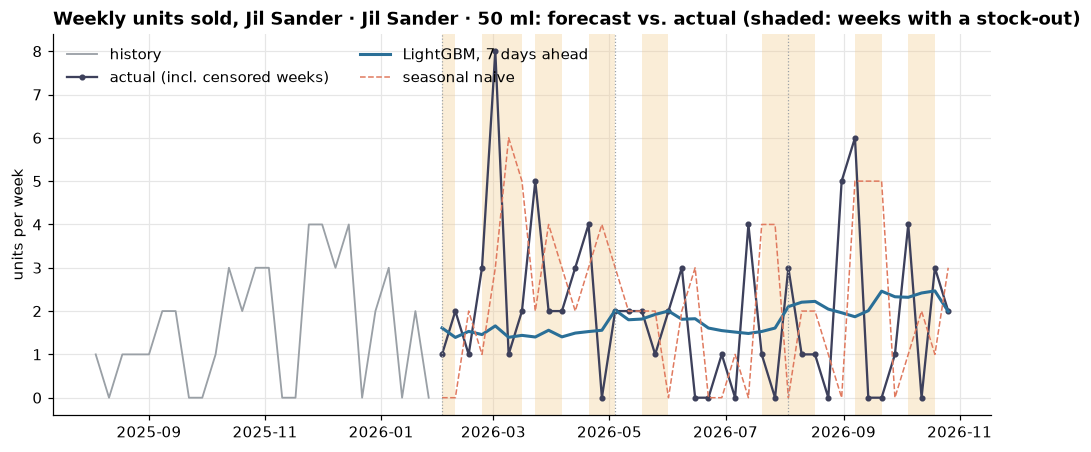

In [9]:
best_size = top_sizes[0]
one = (
    test[test["variant_id"] == best_size]
    .assign(week=lambda t: t["day"].dt.to_period("W-SUN").dt.start_time)
    .groupby("week")
    .agg(
        actual=("units_sold", "sum"),
        lightgbm=("lightgbm", "sum"),
        seasonal_naive=("seasonal_naive", "sum"),
        censored_days=("is_demand_censored", "sum"),
    )
)
history = (
    features[(features["variant_id"] == best_size) & (features["day"] < ORIGINS[0])]
    .assign(week=lambda t: t["day"].dt.to_period("W-SUN").dt.start_time)
    .groupby("week")["units_sold"].sum()
    .iloc[-26:]
)
title = names.set_index("variant_id").loc[best_size, "perfume"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(history.index, history, color=plots.MUTED, lw=1.2, label="history")
ax.plot(one.index, one["actual"], color=plots.PALETTE[2], lw=1.5, marker="o", ms=3, label="actual (incl. censored weeks)")
ax.plot(one.index, one["lightgbm"], color=plots.ACCENT, lw=2, label="LightGBM, 7 days ahead")
ax.plot(one.index, one["seasonal_naive"], color=plots.PALETTE[1], lw=1, ls="--", label="seasonal naive")
for week, row in one[one["censored_days"] > 0].iterrows():
    ax.axvspan(week, week + pd.Timedelta(days=7), color=plots.PALETTE[4], alpha=0.35, lw=0)
for origin in ORIGINS:
    ax.axvline(pd.Timestamp(origin), color=plots.MUTED, lw=0.8, ls=":")
ax.set_title(f"Weekly units sold, {title}: forecast vs. actual (shaded: weeks with a stock-out)")
ax.set_ylabel("units per week")
ax.legend(loc="upper left", ncols=2)
plots.save_figure(fig, "05_forecast_vs_actual")
plt.show()

The forecast follows the level of each size well but **under-reacts to the 8 March spike**: the
model has seen only two Marches, and at the level of a single bottle the gift weeks add a few
units, too few for the trees to separate from noise. (A last-year seasonal index as an extra feature
didn't help on earlier validation origins.) The standard next step is a top-down hierarchical
forecast: forecast the shop's total, where seasonality is strong and clear, and split it by each
size's recent share.

## What masking changes

Censored days aren't simply zeros. The day a size sells out always has a sale (the last units go),
and the days after it carry only the occasional backorder. Both distort an unmasked model: the
sell-out days look like demand spikes, and the empty days look like demand vanishing. The same
LightGBM trained *without* masking (censored days kept as ordinary sales, and as lag inputs),
scored on the same observed days of the last origin:

In [10]:
def unmasked_model(origin: str) -> tuple[lgb.LGBMRegressor, pd.DataFrame]:
    """LightGBM on the raw series: censored days as ordinary sales, in training and in the lags."""
    start = pd.Timestamp(origin)
    stop = start - pd.Timedelta(weeks=8)
    plain = panel["units_sold"].groupby(panel["variant_id"])
    naive_features = features.copy()
    for n in LAGS:
        naive_features[f"units_sold_lag{n}"] = plain.shift(n)
    shifted_plain = plain.shift(7).groupby(panel["variant_id"])
    naive_features["mean_4w"] = shifted_plain.transform(lambda s: s.rolling(28, min_periods=7).mean())
    naive_features["mean_13w"] = shifted_plain.transform(lambda s: s.rolling(91, min_periods=28).mean())
    naive_features["mean_52w"] = shifted_plain.transform(lambda s: s.rolling(364, min_periods=91).mean())
    history = naive_features[(naive_features["day"] < start) & naive_features["mean_13w"].notna()]
    fit, early = history[history["day"] < stop], history[history["day"] >= stop]
    model = lgb.LGBMRegressor(**PARAMS)
    model.fit(fit[FEATURES], fit["units_sold"], eval_set=[(early[FEATURES], early["units_sold"])],
              callbacks=[lgb.early_stopping(150, verbose=False)])
    return model, naive_features


last = ORIGINS[-1]
plain_model, plain_features = unmasked_model(last)
last_scored = scored[scored["origin"] == last]
keys = last_scored[["variant_id", "day"]]
plain_rows = plain_features.merge(keys, on=["variant_id", "day"], how="inner")
plain_pred = plain_model.predict(plain_rows[FEATURES])
comparison = pd.DataFrame(
    {
        "WAPE (daily)": [metrics.wape(last_scored["units_sold"], last_scored["lightgbm"]),
                         metrics.wape(plain_rows["units_sold"], plain_pred)],
        "forecast / actual units": [last_scored["lightgbm"].sum() / last_scored["units_sold"].sum(),
                                    plain_pred.sum() / plain_rows["units_sold"].sum()],
    },
    index=["masked (censored days left out)", "unmasked (censored days as ordinary sales)"],
)
comparison

,WAPE (daily),forecast / actual units
masked (censored days left out),1.807,0.991
unmasked (censored days as ordinary sales),1.870,1.060


Masking keeps the forecast level right (total forecast within about 1 % of the actual units),
while the unmasked model drifts by several percent and has a higher WAPE: the bias that censoring
introduces, measured.

## Reorder points

The shop reorders a size when it's down to 1 unit, and the supplier delivers in 5–21 days. With the
forecast, the reorder point for a 95 % chance of not running out during the lead time is

ROP = d · L + z · √(L · σ_d² + d² · σ_L²)

where d is the forecast daily demand (mean of the last test window), σ_d the standard deviation of
daily forecast errors for that size, L = 13 days the mean lead time and σ_L = 4.6 days its
standard deviation (uniform on 5–21), z = 1.645.

In [11]:
LEAD_MEAN, LEAD_SD, Z = 13.0, (21 - 5) / np.sqrt(12), norm.ppf(0.95)
last_window = test[test["origin"] == last]
errors = scored[scored["origin"] == last].assign(error=lambda t: t["units_sold"] - t["lightgbm"])
reorder = (
    last_window.groupby("variant_id")
    .agg(forecast_per_day=("lightgbm", "mean"), stock_out_days=("is_demand_censored", "sum"))
    .join(errors.groupby("variant_id")["error"].std().rename("error_sd"))
    .join(names.set_index("variant_id")["perfume"])
)
reorder["reorder_point"] = np.ceil(
    reorder["forecast_per_day"] * LEAD_MEAN
    + Z * np.sqrt(LEAD_MEAN * reorder["error_sd"] ** 2 + reorder["forecast_per_day"] ** 2 * LEAD_SD**2)
)
reorder["current_rule"] = 1
top_reorder = reorder.sort_values("forecast_per_day", ascending=False).head(12)
top_reorder.set_index("perfume")[["forecast_per_day", "error_sd", "reorder_point", "current_rule", "stock_out_days"]]

,forecast_per_day,error_sd,reorder_point,current_rule,stock_out_days
perfume,,,,,
Davidoff · Davidoff Cool Water Woman · 30 ml,0.461,1.097,14.0,1,55
Davidoff · Davidoff Cool Water Woman · 50 ml,0.447,0.869,12.0,1,58
Dior · Hypnotic Poison · 30 ml,0.372,0.557,10.0,1,62
Hugo Boss · Boss Alive · 30 ml,0.351,0.741,10.0,1,42
Jil Sander · Jil Sander · 30 ml,0.346,0.276,8.0,1,48
Zarkoperfume · Vanilla Blend · 30 ml,0.336,0.513,9.0,1,48
Zarkoperfume · Vanilla Blend · 50 ml,0.324,1.226,12.0,1,58
Hugo Boss · Boss Alive · 50 ml,0.322,0.672,9.0,1,47
Davidoff · Davidoff Cool Water Man · 30 ml,0.316,0.597,9.0,1,51


**Business action.** For the best sellers the forecast-based reorder point is 8–14 units, not one.
With a 5–21 day lead time, a size that sells a unit every two or three days is bound to run out
before the supplier delivers under the current "reorder at 1" rule, and the last 13 weeks show it
does: these sizes were out of stock on 42–62 of 91 days. Raising the reorder point for the top sizes only (most sizes sell
so rarely that 1–2 units is right) cuts lost sales where they happen, at the cost of a few
more bottles on the shelf.

## Checks

In [12]:
weekly_all, class_all = weekly_wape.loc["all origins"], class_wape.loc["all origins"]
print(f"WAPE per size and week: LightGBM {weekly_all['LightGBM']:.3f} vs seasonal naive {weekly_all['seasonal naive']:.3f}; "
      f"daily per size class: {class_all['LightGBM']:.3f} vs {class_all['seasonal naive']:.3f}; "
      f"per size and day: {daily_wape.loc['all origins', 'LightGBM']:.3f} vs {daily_wape.loc['all origins', 'seasonal naive']:.3f}")
assert not scored["is_demand_censored"].any(), "censored days must not be scored"
lag_reads_censored = features["is_demand_censored"].groupby(features["variant_id"]).shift(7, fill_value=False).astype(bool)
assert features.loc[lag_reads_censored, "units_sold_lag7"].isna().all(), "a lag must never read a censored day"
for table in (weekly_wape, class_wape, shop_wape):
    assert (table["LightGBM"] < table["seasonal naive"]).all(), "LightGBM should beat seasonal naive on WAPE in every origin"
assert daily_wape.loc["all origins", "RMSE LightGBM"] < daily_wape.loc["all origins", "RMSE seasonal naive"]
assert abs(comparison.iloc[0, 1] - 1) < abs(comparison.iloc[1, 1] - 1), "masking should keep the level closer"
print("05 checks passed")

WAPE per size and week: LightGBM 1.214 vs seasonal naive 1.382; daily per size class: 0.366 vs 0.536; per size and day: 1.809 vs 1.815
05 checks passed
